# Skin to CAD: segment, fit, hand off as STEP

A triangle skin -- an STL from a scan or a 3-D-printing download -- is thousands of
flat facets a CAD tool cannot dimension or edit. meshio++ does the mesh-side half of
reverse engineering it with no CAD kernel in the loop, and the CAD half through an
optional OpenCASCADE backend:

- **`segment`** groups the facets into smooth patches bounded by the feature edges,
  with a curvature test that separates a fillet from the faces it is tangent to;
- **`fit_primitives`** fits a plane, sphere, cylinder, cone or torus to each patch and
  reports the residual -- a recovered radius or axis is a measurement;
- the **`step`** writer hands the closed skin to CAD as a faceted solid;
- **`fit_cad`** (a core built with `-DMESHIOPLUSPLUS_WITH_OCCT=ON`) turns the fitted
  patches into analytic CAD faces, sewn into a checked solid and written as STEP.

The part here is a noisy, tessellated turned part with every primitive type in it.
See [skin to CAD](../../doc/cad_fit.md).

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
os.environ.setdefault('VTK_DEFAULT_OPENGL_WINDOW', 'vtkEGLRenderWindow')  # no X server
import meshioplusplus as mp  # noqa: E402

# Head-less, static rendering (no display / live server needed).
pv.OFF_SCREEN = True
pv.set_jupyter_backend('static')
TMP = tempfile.mkdtemp()
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')
TYPES = ['none', 'plane', 'sphere', 'cylinder', 'cone', 'torus']
TYPE_COLORS = ['#888888', '#4c78a8', '#f58518', '#54a24b', '#e45756', '#b279a2']


def to_grid(mesh):
    '''A PyVista grid of a meshio++ mesh, through a temporary .vtu.'''
    target = os.path.join(TMP, 'render.vtu')
    mp.write(target, mesh)
    return pv.read(target)


def render(mesh, title, scalars=None, cmap='tab10', clim=None, annotations=None, save=None,
           view=(1.0, -1.6, 0.9)):
    '''Render with PyVista, or the points with matplotlib when GL is unavailable.'''
    fig, ax = plt.subplots(figsize=(9, 6))
    try:
        grid = to_grid(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(1000, 720))
        kwargs = {'show_edges': True, 'edge_color': '#333333', 'line_width': 0.2}
        if scalars is not None:
            bar = {'title': scalars, 'vertical': True, 'position_x': 0.86,
                   'position_y': 0.15, 'height': 0.7, 'width': 0.06}
            if annotations:
                bar['n_labels'] = 0
            kwargs.update(scalars=scalars, cmap=cmap, clim=clim, categories=True,
                          annotations=annotations, scalar_bar_args=bar)
        else:
            kwargs['color'] = '#2ec4b6'
        pl.add_mesh(grid, **kwargs)
        pl.view_vector(view, viewup=(0, 0, 1))
        pl.reset_camera()
        pl.camera.zoom(1.15)
        img = pl.screenshot(return_img=True)
        pl.close()
        ax.imshow(img)
        if save:
            try:
                os.makedirs(DOC_IMAGES, exist_ok=True)
                plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
            except Exception as exc:  # pragma: no cover - read-only checkout
                print('doc image not written:', exc)
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)
        p = np.asarray(mesh.points)
        ax.scatter(p[:, 0], p[:, 2], s=1)
    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## A noisy turned part

A surface of revolution closed by two triangle fans: a flat **base**, a **cylinder**
wall, a toroidal **fillet** tangent to the wall and to a flat **shoulder**, a
**cone**, and a shallow spherical **dome**. The base, shoulder, cone and dome meet
their neighbours at creases; the fillet meets the wall and the shoulder tangentially,
so only its curvature tells it apart. Every point is moved by up to `1e-3`, a scan's
noise.

points: 2178  cells: 2240
{'boundary_edges': 0, 'non_manifold_edges': 0, 'inconsistent_pairs': 0, 'degenerate_triangles': 0, 'watertight': True}


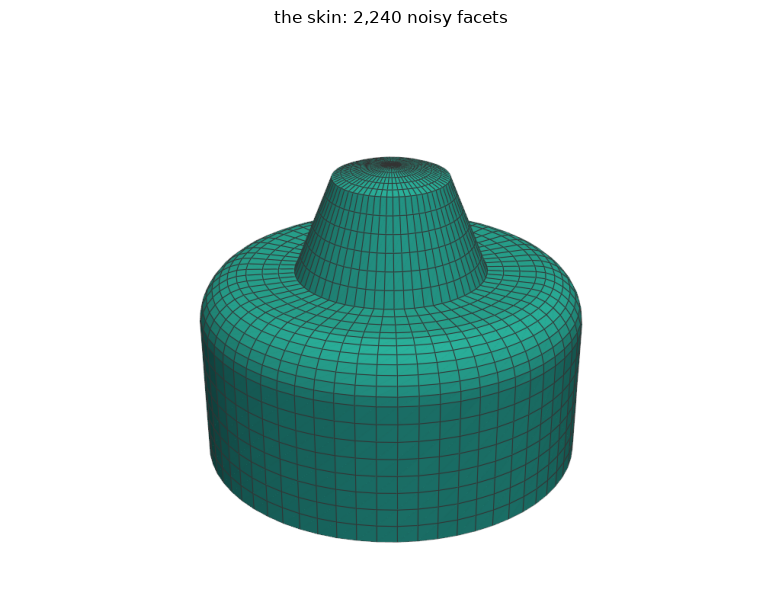

In [2]:
def turned_part(n=64, noise=0.0, seed=7):
    prof = [(2.0 * i / 4, 0.0) for i in range(1, 5)]                       # base
    prof += [(2.0, 1.5 * i / 8) for i in range(1, 9)]                       # wall
    prof += [(1.5 + 0.5 * np.cos(a), 1.5 + 0.5 * np.sin(a))                 # fillet
             for a in np.linspace(0.0, np.pi / 2, 9)[1:]]
    prof += [(1.5 - 0.5 * i / 3, 2.0) for i in range(1, 4)]                 # shoulder
    prof += [(1.0 - 0.4 * i / 6, 2.0 + 1.0 * i / 6) for i in range(1, 7)]   # cone
    zc, big_r = 1.625, 1.5                                                   # dome
    a0 = np.arcsin(0.6 / big_r)
    prof += [(big_r * np.sin(a), zc + big_r * np.cos(a)) for a in np.linspace(a0, 0.0, 7)[1:-1]]
    pts = [[0.0, 0.0, 0.0]]
    for r, z in prof:
        for k in range(n):
            t = 2.0 * np.pi * k / n
            pts.append([r * np.cos(t), r * np.sin(t), z])
    top = len(pts)
    pts.append([0.0, 0.0, zc + big_r])
    ring = lambda i, k: 1 + i * n + (k % n)  # noqa: E731
    last = len(prof) - 1
    tris = [[0, ring(0, k + 1), ring(0, k)] for k in range(n)]
    tris += [[top, ring(last, k), ring(last, k + 1)] for k in range(n)]
    quads = [[ring(i, k), ring(i, k + 1), ring(i + 1, k + 1), ring(i + 1, k)]
             for i in range(last) for k in range(n)]
    pts = np.array(pts)
    if noise:
        pts = pts + noise * np.random.default_rng(seed).uniform(-1.0, 1.0, pts.shape)
    return mp.Mesh(pts, [('triangle', np.array(tris)), ('quad', np.array(quads))])


part = turned_part(noise=1e-3)
print('points:', len(part.points), ' cells:', sum(len(c.data) for c in part.cells))
print(mp.surface_watertight_check(part))
render(part, 'the skin: 2,240 noisy facets')

## Segment

The feature edges alone find four patches: the fillet joins the wall and the shoulder,
because nothing creases between them. `curvature_tolerance` compares each cell's
curvature estimate (about the larger principal curvature: `1/r` on the wall, `1/0.5`
on the fillet, `0` on the planes) with the mean of the patch it would join; the noise
makes a few slivers near the poles, which `min_patch_cells` folds back in.

creases only     : 4 patches
with curvature   : {'num_patches': 6, 'num_merged': 85, 'num_feature_edges': 192, 'num_boundary_edges': 0, 'num_non_manifold_edges': 0}
patch sizes      : [256, 384, 512, 512, 192, 384]
adjacency (a, b, shared edges):
[[ 0  2 64]
 [ 1  5 64]
 [ 2  3 64]
 [ 3  4 64]
 [ 4  5 64]]


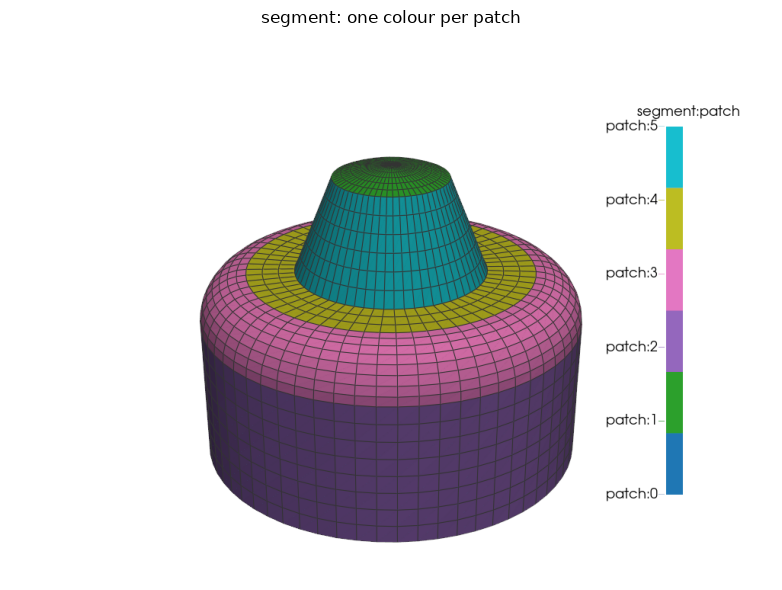

In [3]:
creases_only = mp.segment(part, return_report=True)[1]
print('creases only     :', creases_only['num_patches'], 'patches')

seg, report = mp.segment(part, curvature_tolerance=1.0, min_patch_cells=20, return_report=True)
print('with curvature   :', report)
print('patch sizes      :', np.bincount(np.concatenate(seg.cell_data['segment:patch'])).tolist())
print('adjacency (a, b, shared edges):')
print(seg.field_data['segment:adjacency'])
patches = {k: f'patch:{k}' for k in range(report['num_patches'])}
render(seg, 'segment: one colour per patch', scalars='segment:patch',
       annotations=patches, save='skin_to_cad_patches')

## Fit primitives

Each patch is fitted with every type, refined by Levenberg-Marquardt on the orthogonal
distance, and the simplest type within tolerance (here `2e-3` of the patch's diagonal)
wins. The parameters are the measurement: the wall's radius is 2, the fillet a torus of
major radius 1.5 and minor radius 0.5, the cone's half-angle 21.8 degrees, the dome a
sphere of radius 1.5 -- recovered through the noise, with the residual to prove it.

In [4]:
fit, fit_report = mp.fit_primitives(seg, tolerance=2e-3, return_report=True)
print(fit_report)
fd = fit.field_data
print(f"{'patch':>5} {'type':>9} {'rms':>9}  parameters")
for pid, t, p, rms in zip(fd['fit:patch_id'], fd['fit:patch_type'],
                          fd['fit:patch_params'], fd['fit:patch_rms']):
    name = TYPES[t]
    if name == 'plane':
        what = f'normal {np.round(p[3:6], 3)}'
    elif name == 'sphere':
        what = f'centre {np.round(p[:3], 3)}, radius {p[6]:.4f}'
    elif name == 'cylinder':
        what = f'axis {np.round(p[3:6], 3)}, radius {p[6]:.4f}'
    elif name == 'cone':
        what = f'apex {np.round(p[:3], 3)}, half-angle {p[8]:.2f} deg'
    else:
        what = f'major {p[6]:.4f}, minor {p[7]:.4f}'
    print(f'{pid:>5} {name:>9} {rms:9.2e}  {what}')

{'num_patches': 6, 'num_plane': 2, 'num_sphere': 1, 'num_cylinder': 1, 'num_cone': 1, 'num_torus': 1, 'num_unfitted': 0}
patch      type       rms  parameters
    0     plane  5.81e-04  normal [-0.  0. -1.]
    1    sphere  5.52e-04  centre [-0.    -0.     1.624], radius 1.5006
    2  cylinder  5.78e-04  axis [-0. -0.  1.], radius 2.0000
    3     torus  5.70e-04  major 1.5001, minor 0.4998
    4     plane  5.30e-04  normal [-0.  0.  1.]
    5      cone  5.77e-04  apex [0.  0.  4.5], half-angle 21.80 deg


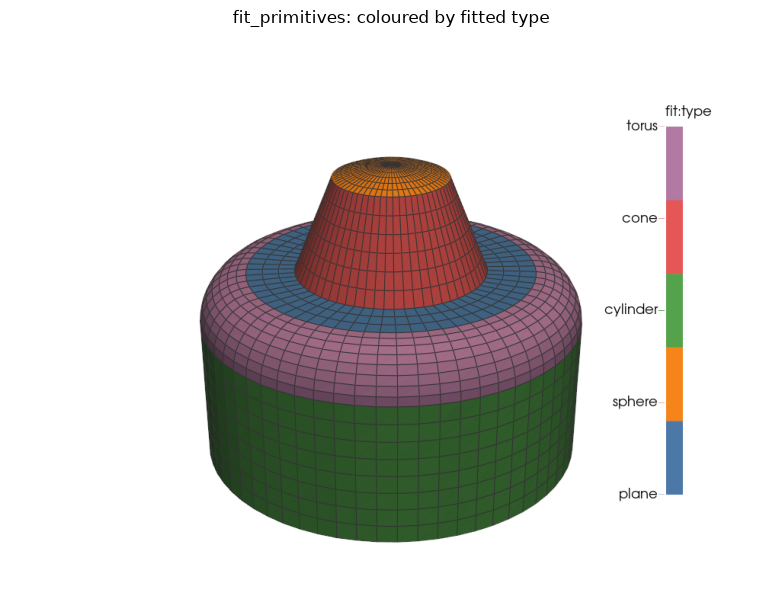

In [5]:
annotations = {i: TYPES[i] for i in range(1, 6)}
render(fit, 'fit_primitives: coloured by fitted type', scalars='fit:type',
       cmap=TYPE_COLORS[1:], clim=[1, 5], annotations=annotations, save='skin_to_cad_fits')

## A fit that does not hold is reported, not rounded

With the tolerance tighter than the noise, nothing is accepted: every patch comes back
as `none` with its best residual, so a downstream tool never mistakes noise for a
primitive.

In [6]:
tight = mp.fit_primitives(seg, tolerance=1e-5, return_report=True)[1]
print(tight)

{'num_patches': 6, 'num_plane': 0, 'num_sphere': 0, 'num_cylinder': 0, 'num_cone': 0, 'num_torus': 0, 'num_unfitted': 6}


## Hand off as STEP

The closed skin goes to CAD as a faceted solid: one planar `ADVANCED_FACE` per facet
(non-planar noisy quads are fanned into triangles), shared edges, one
`MANIFOLD_SOLID_BREP`. A CAD tool opens it as a solid it can measure and section; the
fitted parameters above say which faces belong to which cylinder or cone.

In [7]:
step_path = os.path.join(TMP, 'turned_part.step')
mp.write(step_path, part)
text = open(step_path).read()
print('\n'.join(text.splitlines()[:9]))
for entity in ('ADVANCED_FACE', 'EDGE_CURVE', 'VERTEX_POINT', 'MANIFOLD_SOLID_BREP'):
    print(f'{entity:>20}: {text.count("=" + entity + "(")}')

ISO-10303-21;
/*
Written by meshio++ v16.44.0
*/
HEADER;
FILE_DESCRIPTION(('meshio++ faceted B-rep'),'2;1');
FILE_NAME('turned_part.step','1970-01-01T00:00:00',(''),(''),'meshio++','meshio++','');
FILE_SCHEMA(('AUTOMOTIVE_DESIGN { 1 0 10303 214 1 1 1 1 }'));
ENDSEC;
       ADVANCED_FACE: 4352
          EDGE_CURVE: 6528
        VERTEX_POINT: 2178
 MANIFOLD_SOLID_BREP: 1


## Analytic CAD faces with `fit_cad`

The faceted solid is a hand-off; the fitted surfaces are what a CAD tool wants. With the
optional OpenCASCADE backend, `fit_cad` makes each accepted patch one face on its fitted
surface, trimmed by the patch boundary: exact circles where a plane meets the cylinder,
the cone or the dome, B-splines where the fillet meets the wall and the shoulder
tangentially. OpenCASCADE sews and checks the solid, and any face it rejects, or that
strays further than the tolerance from the skin, would come back faceted and be counted
in `num_demoted`. The report compares the solid with the skin: its volume ratio and the
Hausdorff deviation of its re-meshed surface. See [fit CAD](../../doc/fit_cad.md).

{'valid': True, 'num_faces': 6, 'num_plane': 2, 'num_sphere': 1, 'num_cylinder': 1, 'num_cone': 1, 'num_torus': 1, 'num_faceted_faces': 0, 'num_demoted': 0, 'num_exact_edges': 5, 'num_approx_edges': 5}
volume ratio 1.00218, max deviation 8.91e-03 (tolerance 3.51e-02)
               PLANE: 2
 CYLINDRICAL_SURFACE: 1
     CONICAL_SURFACE: 1
   SPHERICAL_SURFACE: 1
    TOROIDAL_SURFACE: 1
       ADVANCED_FACE: 6


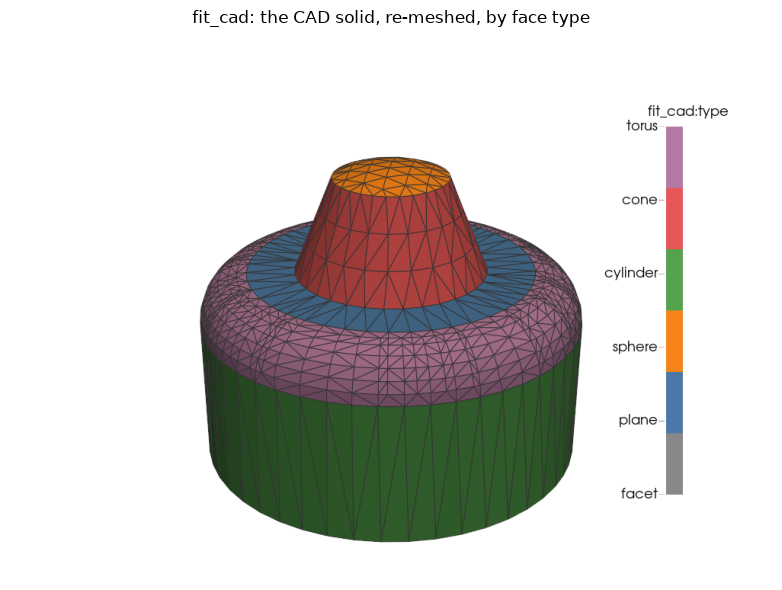

In [8]:
from meshioplusplus._fit_cad import has_occt

if has_occt():
    cad_path = os.path.join(TMP, 'turned_part_cad.step')
    solid, cad = mp.fit_cad(fit, cad_path, return_report=True)
    print({k: cad[k] for k in ('valid', 'num_faces', 'num_plane', 'num_sphere', 'num_cylinder',
                                'num_cone', 'num_torus', 'num_faceted_faces', 'num_demoted',
                                'num_exact_edges', 'num_approx_edges')})
    print(f"volume ratio {cad['volume_ratio']:.5f}, max deviation {cad['max_deviation']:.2e}"
          f" (tolerance {cad['tolerance']:.2e})")
    text = open(cad_path).read()
    for entity in ('PLANE', 'CYLINDRICAL_SURFACE', 'CONICAL_SURFACE', 'SPHERICAL_SURFACE',
                   'TOROIDAL_SURFACE', 'ADVANCED_FACE'):
        print(f'{entity:>20}: {text.count("= " + entity + "(")}')
    render(solid, 'fit_cad: the CAD solid, re-meshed, by face type', scalars='fit_cad:type',
           cmap=TYPE_COLORS, clim=[0, 5], annotations={0: 'facet', **{i: TYPES[i] for i in range(1, 6)}},
           save='fit_cad_solid')
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON '
          'to build the analytic solid (see doc/fit_cad.md).')

## Curled patches, fillets and threads

Three kinds of patch no primitive explains get more than a freeform face:

- a patch that folds over both its best-fit plane and an unrolled cylinder -- here a band
  closed around its axis, whose radius waves along it -- is **split** into pieces that do
  unroll, each its own B-spline face under a new patch label;
- a patch running between two analytic faces is tried as a constant-radius **rolling-ball
  fillet**: the pipe of the fitted radius around the spine where the two surfaces, offset
  by it, meet -- here the foot of a leaning boss, a fillet swept along an ellipse;
- a patch beside a cylinder or cone is tried as a straight **thread flank**, a ruled
  helicoid about its axis -- here both flanks of a trapezoidal thread.

`num_split_patches`, `num_fillet` and `num_helical` count them; `fit_cad:type` is 6 for a
freeform B-spline, 7 for a fillet and 8 for a thread face. See
[fit CAD](../../doc/fit_cad.md#fillets-blends-and-threads).

In [9]:
def closed_revolve(prof, z0, z1, n):
    pts = [[0.0, 0.0, z0]] + [[r * np.cos(2 * np.pi * k / n), r * np.sin(2 * np.pi * k / n), z]
                              for r, z in prof for k in range(n)] + [[0.0, 0.0, z1]]
    ring = lambda i, k: 1 + i * n + (k % n)  # noqa: E731
    last, top = len(prof) - 1, len(pts) - 1
    tris = [[0, ring(0, k + 1), ring(0, k)] for k in range(n)]
    tris += [[top, ring(last, k), ring(last, k + 1)] for k in range(n)]
    for i in range(last):
        for k in range(n):
            tris += [[ring(i, k), ring(i, k + 1), ring(i + 1, k + 1)],
                     [ring(i, k), ring(i + 1, k + 1), ring(i + 1, k)]]
    return mp.Mesh(np.array(pts), [('triangle', np.array(tris))])


def wavy_capped(n=96, m=64):
    '''A capped band whose radius waves along z: r = 1 + 0.15 sin(2 pi z).'''
    prof = [(i / 3, 0.0) for i in range(1, 4)]
    prof += [(1 + 0.15 * np.sin(4 * np.pi * i / m), 2 * i / m) for i in range(1, m + 1)]
    return closed_revolve(prof + [(2 / 3, 2.0), (1 / 3, 2.0)], 0.0, 2.0, n)


class Skin:
    '''Triangles wound along an expected outward direction.'''
    def __init__(self):
        self.pts, self.tris = [], []

    def add(self, p):
        self.pts.append(list(map(float, p)))
        return len(self.pts) - 1

    def tri(self, a, b, c, out):
        p, q, r = (np.asarray(self.pts[i]) for i in (a, b, c))
        self.tris.append([a, b, c] if np.dot(np.cross(q - p, r - p), out) >= 0 else [a, c, b])

    def quads(self, ra, rb, out):
        for i in range(len(ra)):
            j = (i + 1) % len(ra)
            self.tri(ra[i], ra[j], rb[j], out(i))
            self.tri(ra[i], rb[j], rb[i], out(i))

    def mesh(self):
        return mp.Mesh(np.array(self.pts), [('triangle', np.array(self.tris))])


def inclined_boss(alpha=20.0, r=0.6, rf=0.2, h=1.5, plate=1.6, t=0.4, n=96, k=8):
    '''A boss leaning alpha degrees on a round plate, its foot rounded by a
    concave fillet of radius rf: a canal surface along an ellipse.'''
    al = np.radians(alpha)
    ax, e1, ez = np.array([np.sin(al), 0, np.cos(al)]), np.array([np.cos(al), 0, -np.sin(al)]), np.array([0, 0, 1.0])
    b, rows, centre, unit, foot = Skin(), [[] for _ in range(k + 1)], [], [], []
    for i in range(n):
        th = 2 * np.pi * i / n
        u = np.cos(th) * e1 + np.array([0, np.sin(th), 0])
        hh = (rf + (r + rf) * np.sin(al) * np.cos(th)) / np.cos(al)
        c = hh * ax + (r + rf) * u
        centre.append(c), unit.append(u), foot.append(hh)
        w = np.arccos(np.clip(u[2], -1, 1))
        for j in range(k + 1):
            s = j / k
            rows[j].append(b.add(c - rf * (np.sin(s * w) * u + np.sin((1 - s) * w) * ez) / np.sin(w)))
    for j in range(k):
        b.quads(rows[j], rows[j + 1], lambda i, j=j: centre[i] - b.pts[rows[j][i]])
    prev = rows[k]
    for j in range(1, 9):
        row = [b.add((foot[i] + (h - foot[i]) * j / 8) * ax + r * unit[i]) for i in range(n)]
        b.quads(prev, row, lambda i: unit[i])
        prev = row
    top = b.add(h * ax)
    for i in range(n):
        b.tri(top, prev[i], prev[(i + 1) % n], ax)
    inner = rows[0]
    psi = [np.arctan2(b.pts[v][1], b.pts[v][0]) for v in inner]
    rho = [np.hypot(*b.pts[v][:2]) for v in inner]
    for j in range(1, 7):
        row = [b.add([(rho[i] + (plate - rho[i]) * j / 6) * np.cos(psi[i]),
                      (rho[i] + (plate - rho[i]) * j / 6) * np.sin(psi[i]), 0]) for i in range(n)]
        b.quads(inner, row, lambda i: ez)
        inner = row
    lower = [b.add([plate * np.cos(p), plate * np.sin(p), -t]) for p in psi]
    b.quads(inner, lower, lambda i: np.array([np.cos(psi[i]), np.sin(psi[i]), 0]))
    bottom = b.add([0, 0, -t])
    for i in range(n):
        b.tri(bottom, lower[i], lower[(i + 1) % n], -ez)
    return b.mesh()


def threaded_rod(pitch=0.5, r0=0.8, r1=1.0, turns=3, n=64):
    '''A trapezoidal thread, r = f(z - K theta): root and crest cylinders,
    both flanks ruled helicoids, closed by two shallow end fans.'''
    k, w, rad, at = pitch / (2 * np.pi), [], [], 0.0
    for s, (seg, sub) in enumerate(zip([0.26, 0.24, 0.26, 0.24], [2, 3, 2, 3])):
        for i in range(sub):
            w.append(at + seg * pitch * i / sub)
            rad.append([r0, r0 + (r1 - r0) * i / sub, r1, r1 - (r1 - r0) * i / sub][s])
        at += seg * pitch
    per, b = len(w), Skin()
    rows = per * turns
    ids = [[b.add([rad[j % per] * np.cos(2 * np.pi * i / n), rad[j % per] * np.sin(2 * np.pi * i / n),
                   w[j % per] + pitch * (j // per) + k * 2 * np.pi * i / n]) for j in range(rows + 1)]
           for i in range(n)]
    node = lambda i, j: ids[i][j] if i < n else (ids[0][j + per] if j + per <= rows else -1)  # noqa: E731
    for i in range(n):
        for j in range(rows):
            a, bb, c, d = node(i, j), node(i + 1, j), node(i + 1, j + 1), node(i, j + 1)
            if bb < 0 or c < 0:
                continue
            pa, pd = np.asarray(b.pts[a]), np.asarray(b.pts[d])
            ra, rd = np.hypot(*pa[:2]), np.hypot(*pd[:2])
            out = np.array([pa[0] / ra, pa[1] / ra, -1.0 if rd > ra + 1e-12 else (1.0 if rd < ra - 1e-12 else 0.0)])
            b.tri(a, bb, c, out), b.tri(a, c, d, out)

    def fan(loop, reverse):
        zs = [b.pts[v][2] for v in loop]
        c = b.add([0, 0, max(zs) + pitch if reverse else min(zs) - pitch])
        for i in range(len(loop)):
            p, q = loop[i], loop[(i + 1) % len(loop)]
            b.tris.append([c, q, p] if reverse else [c, p, q])

    fan([node(i, 0) for i in range(n)] + [node(0, j) for j in range(per, 0, -1)], True)
    fan([node(i, rows) for i in range(n)] + [node(n - 1, j) for j in range(rows - 1, rows - per - 1, -1)], False)
    return b.mesh()

  a band closed around its axis, split: valid True, 4 faces -- split 2, B-spline 2, fillet 0, thread 0, faceted 0; deviation 2.7e-03 (tolerance 8.5e-03)


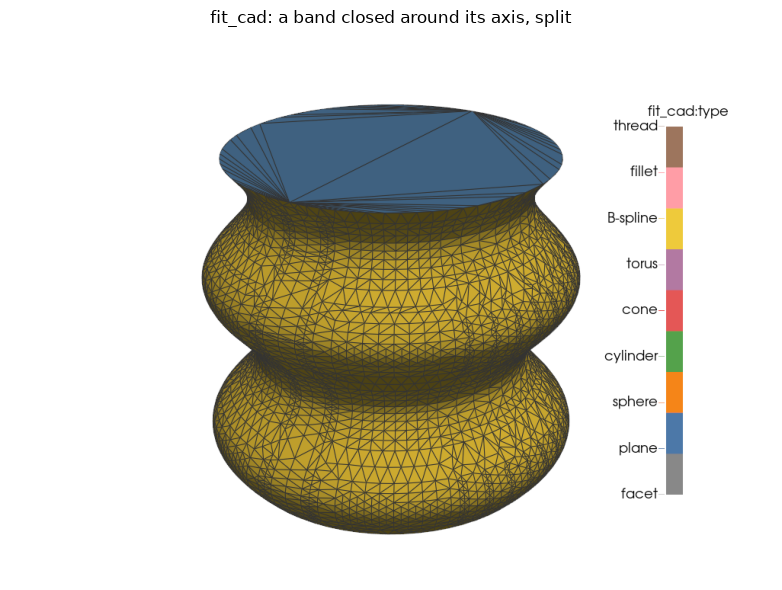

       a fillet swept along an ellipse: valid True, 6 faces -- split 0, B-spline 0, fillet 1, thread 0, faceted 0; deviation 1.3e-02 (tolerance 1.4e-02)


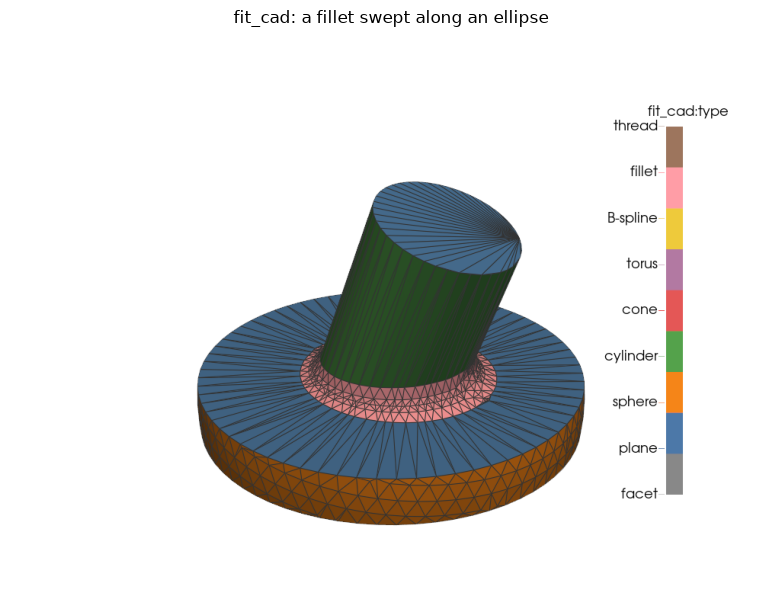

                  a trapezoidal thread: valid True, 137 faces -- split 0, B-spline 0, fillet 0, thread 2, faceted 128; deviation 3.2e-03 (tolerance 9.8e-03)


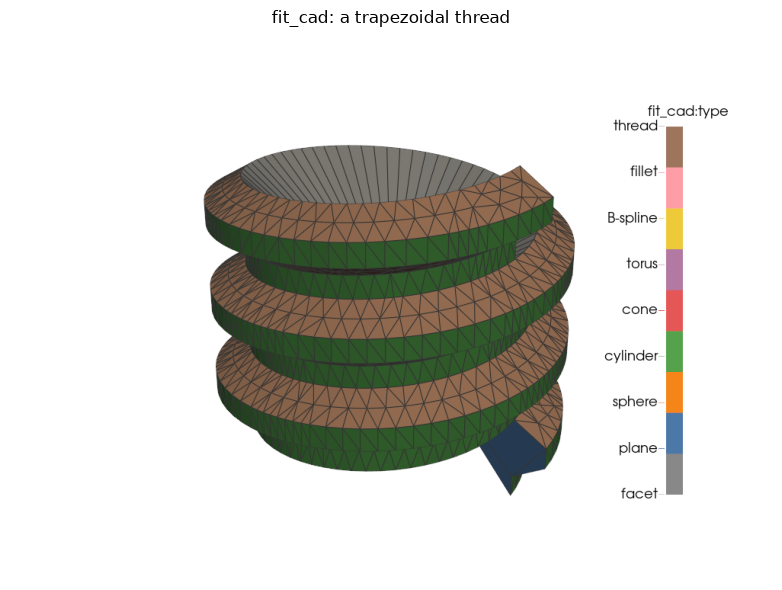

In [10]:
FEATURE_COLORS = TYPE_COLORS + ['#eeca3b', '#ff9da6', '#9d755d']
FEATURES = {0: 'facet', **{i: TYPES[i] for i in range(1, 6)}, 6: 'B-spline', 7: 'fillet', 8: 'thread'}
cases = [('a band closed around its axis, split', wavy_capped(), 0.0, 'fit_cad_split'),
         ('a fillet swept along an ellipse', inclined_boss(), 3.0, 'fit_cad_fillet'),
         ('a trapezoidal thread', threaded_rod(), 0.0, 'fit_cad_thread')]
if has_occt():
    for title, skin, ctol, save in cases:
        fitted = mp.fit_primitives(mp.segment(skin, curvature_tolerance=ctol))
        solid, cad = mp.fit_cad(fitted, return_report=True)
        print(f"{title:>38}: valid {cad['valid']}, {cad['num_faces']} faces -- "
              f"split {cad['num_split_patches']}, B-spline {cad['num_bspline']}, "
              f"fillet {cad['num_fillet']}, thread {cad['num_helical']}, "
              f"faceted {cad['num_faceted_faces']}; deviation {cad['max_deviation']:.1e}"
              f" (tolerance {cad['tolerance']:.1e})")
        render(solid, f'fit_cad: {title}', scalars='fit_cad:type', cmap=FEATURE_COLORS,
               clim=[0, 8], annotations=FEATURES, save=save)
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')

## Fillets of varying radius, blends and rounded threads

What one radius, two analytic neighbours or a straight flank about a neighbouring cylinder
cannot explain is fitted too:

- a **fillet whose radius varies** along it gets one ball radius per vertex, fitted as a law
  along the edge, and a face through the cross-sections of the ball family -- here a block's
  edge rounded by a ball shrinking from 0.3 to 0.2;
- a patch between two fitted faces, one of them a freeform B-spline, is tried as a
  **rolling-ball blend** against them once the freeform faces exist -- here a bar whose wavy
  top and leaning front are both freeform;
- a **thread of any profile** finds its screw from its own facets (the screw motion most
  nearly tangent to the patch) when no cylinder or cone gives an axis -- here a thread whose
  root and crest are rounded arcs, with no cylinder anywhere.

`num_variable_fillet`, `num_blend` and `num_rounded_thread` count them among the fillet
and thread faces.

In [11]:
def loft(loops, centres):
    '''Rows of cross-section loops (points with an outward hint, None pointing away from
    the row's centre) as quads, the two ends closed by fans to the end loops' centroids.'''
    b = Skin()
    ids = [[b.add(p) for p, _ in loop] for loop in loops]
    count = len(ids[0])
    for i in range(len(loops) - 1):
        for j in range(count):
            out = loops[i][j][1]
            out = np.asarray(b.pts[ids[i][j]]) - centres[i] if out is None else np.asarray(out)
            jn = (j + 1) % count
            b.tri(ids[i][j], ids[i + 1][j], ids[i + 1][jn], out)
            b.tri(ids[i][j], ids[i + 1][jn], ids[i][jn], out)
    for i, sign in ((0, -1.0), (len(loops) - 1, 1.0)):
        mid = b.add(np.mean([b.pts[v] for v in ids[i]], axis=0))
        for j in range(count):
            b.tri(mid, ids[i][j], ids[i][(j + 1) % count], np.array([sign, 0, 0]))
    return b.mesh()


def variable_fillet_block(length=2.0, rm=0.25, ra=0.05, n=48, k=16, m=6):
    '''The unit-section block along x whose edge at y = z = 1 is rounded by a ball of radius
    r(x) = rm + ra cos(pi x / length): each fillet row is the exact characteristic circle.'''
    loops, centres = [], []
    for i in range(n + 1):
        x = length * i / n
        r = rm + ra * np.cos(np.pi * x / length)
        dr = -ra * np.pi / length * np.sin(np.pi * x / length)
        c, cd = np.array([x, 1 - r, 1 - r]), np.array([1.0, -dr, -dr])
        delta = -r * dr / np.linalg.norm(cd)
        cc, rho = c + delta * cd / np.linalg.norm(cd), np.sqrt(r * r - delta * delta)
        a = (np.array([x, 1.0, 1 - r]) - cc) / rho
        b2 = np.array([x, 1 - r, 1.0]) - cc
        bv = b2 - np.dot(b2, a) * a
        bv /= np.linalg.norm(bv)
        om = np.arctan2(np.dot(b2, bv), np.dot(b2, a))
        loop = [([x, j / m, 0], [0, 0, -1]) for j in range(m)]
        loop += [([x, 1, (1 - r) * j / m], [0, 1, 0]) for j in range(m)]
        loop += [(cc + rho * (np.cos(om * j / k) * a + np.sin(om * j / k) * bv), None) for j in range(k)]
        loop += [([x, (1 - r) * (1 - j / m), 1], [0, 0, 1]) for j in range(m)]
        loop += [([x, 0, 1 - j / m], [0, -1, 0]) for j in range(m)]
        loops.append(loop), centres.append(c)
    return loft(loops, centres)


def wavy_bar(length=3.0, wave=0.06, twist=3.0, r=0.2, n=96, k=8, m=8):
    '''A bar whose top waves and whose front leans in and out, both freeform and tangent
    to a ball of radius r rolling along (x, 0, wave cos(4 pi x / length)).'''
    loops, centres = [], []
    for i in range(n + 1):
        x = length * i / n
        c = np.array([x, 0.0, wave * np.cos(4 * np.pi * x / length)])
        t = np.array([1.0, 0.0, -wave * 4 * np.pi / length * np.sin(4 * np.pi * x / length)])
        t /= np.linalg.norm(t)
        side = np.array([0.0, 1.0, 0.0])
        m1 = np.cross(t, side)
        psi = np.radians(twist) * np.sin(2 * np.pi * x / length)
        m2 = np.cos(psi) * side + np.sin(psi) * m1
        q1, q2 = c + r * m1, c + r * m2
        w1, w2 = np.cross(m1, t), np.cross(m2, t)
        w1, w2 = (w1 if w1[1] < 0 else -w1), (w2 if w2[2] < 0 else -w2)
        w1, w2 = w1 - w1[0] / t[0] * t, w2 - w2[0] / t[0] * t
        top, low = q1 + (q1[1] + 1) / -w1[1] * w1, q2 + (q2[2] + 1) / -w2[2] * w2
        corner = np.array([top[0], -1.0, -1.0])
        om = np.arccos(np.clip(np.dot(m1, m2), -1, 1))
        loop = [(corner + (top - corner) * j / m, [0, -1, 0]) for j in range(m)]
        loop += [(top + (q1 - top) * j / m, m1) for j in range(m)]
        loop += [(c + r * (np.sin((1 - j / k) * om) * m1 + np.sin(j / k * om) * m2) / np.sin(om), None)
                 for j in range(k)]
        loop += [(q2 + (low - q2) * j / m, m2) for j in range(m)]
        loop += [(low + (corner - low) * j / m, [0, 0, -1]) for j in range(m)]
        loops.append(loop), centres.append(c)
    return loft(loops, centres)


def rounded_thread_rod(pitch=0.5, r0=0.8, r1=1.0, rr=0.2, turns=3, n=64):
    '''threaded_rod's thread with its root and crest flats replaced by circular arcs of
    radius rr (the crest bulging out, the root in), meeting the flanks at a crease.'''
    half = 0.13 * pitch
    d = np.sqrt(rr * rr - half * half)
    k, w, rad, at = pitch / (2 * np.pi), [], [], 0.0
    for s, (seg, sub) in enumerate(zip([0.26, 0.24, 0.26, 0.24], [4, 3, 4, 3])):
        for i in range(sub):
            x = seg * pitch * i / sub - half
            w.append(at + seg * pitch * i / sub)
            rad.append([r0 + d - np.sqrt(rr * rr - x * x), r0 + (r1 - r0) * i / sub,
                        r1 - d + np.sqrt(rr * rr - x * x), r1 - (r1 - r0) * i / sub][s])
        at += seg * pitch
    per, b = len(w), Skin()
    rows = per * turns
    ids = [[b.add([rad[j % per] * np.cos(2 * np.pi * i / n), rad[j % per] * np.sin(2 * np.pi * i / n),
                   w[j % per] + pitch * (j // per) + k * 2 * np.pi * i / n]) for j in range(rows + 1)]
           for i in range(n)]
    node = lambda i, j: ids[i][j] if i < n else (ids[0][j + per] if j + per <= rows else -1)  # noqa: E731
    for i in range(n):
        for j in range(rows):
            a, bb, c, dd = node(i, j), node(i + 1, j), node(i + 1, j + 1), node(i, j + 1)
            if bb < 0 or c < 0:
                continue
            pa, pd = np.asarray(b.pts[a]), np.asarray(b.pts[dd])
            ra, rd = np.hypot(*pa[:2]), np.hypot(*pd[:2])
            out = np.array([pa[0] / ra, pa[1] / ra, -1.0 if rd > ra + 1e-12 else (1.0 if rd < ra - 1e-12 else 0.0)])
            b.tri(a, bb, c, out), b.tri(a, c, dd, out)

    def fan(loop, reverse):
        zs = [b.pts[v][2] for v in loop]
        c = b.add([0, 0, max(zs) + pitch if reverse else min(zs) - pitch])
        for i in range(len(loop)):
            p, q = loop[i], loop[(i + 1) % len(loop)]
            b.tris.append([c, q, p] if reverse else [c, p, q])

    fan([node(i, 0) for i in range(n)] + [node(0, j) for j in range(per, 0, -1)], True)
    fan([node(i, rows) for i in range(n)] + [node(n - 1, j) for j in range(rows - 1, rows - per - 1, -1)], False)
    return b.mesh()

      a fillet of varying radius: valid True, 7 faces -- B-spline 0, fillet 1 (varying 1, blend 0), thread 0 (rounded 0), faceted 0; deviation 2.1e-03 (tolerance 6.7e-03)


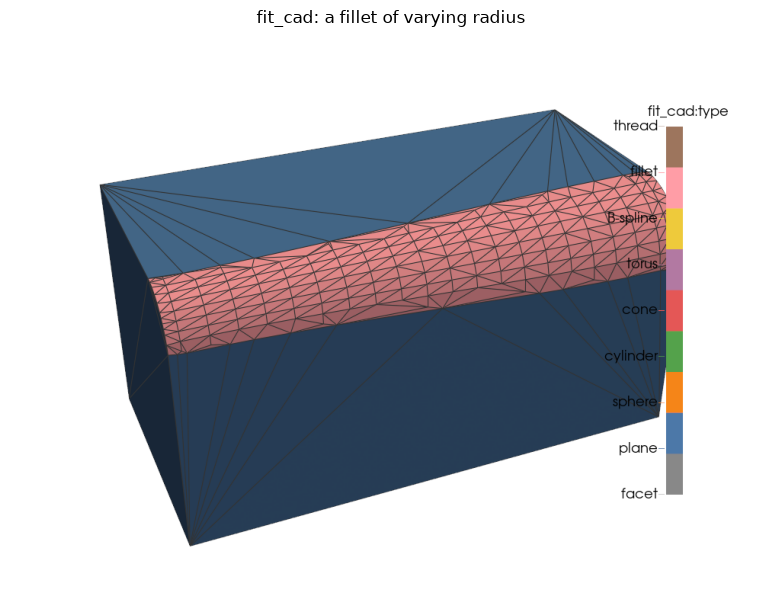

  a blend between freeform faces: valid True, 7 faces -- B-spline 2, fillet 1 (varying 0, blend 1), thread 0 (rounded 0), faceted 0; deviation 5.2e-03 (tolerance 9.8e-03)


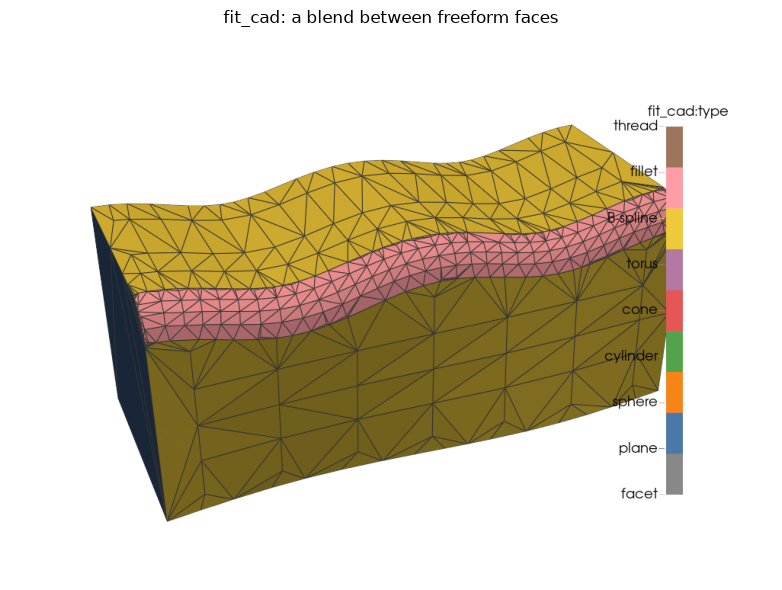

   a rounded thread, no cylinder: valid True, 137 faces -- B-spline 0, fillet 0 (varying 0, blend 0), thread 4 (rounded 2), faceted 128; deviation 2.1e-03 (tolerance 4.3e-03)


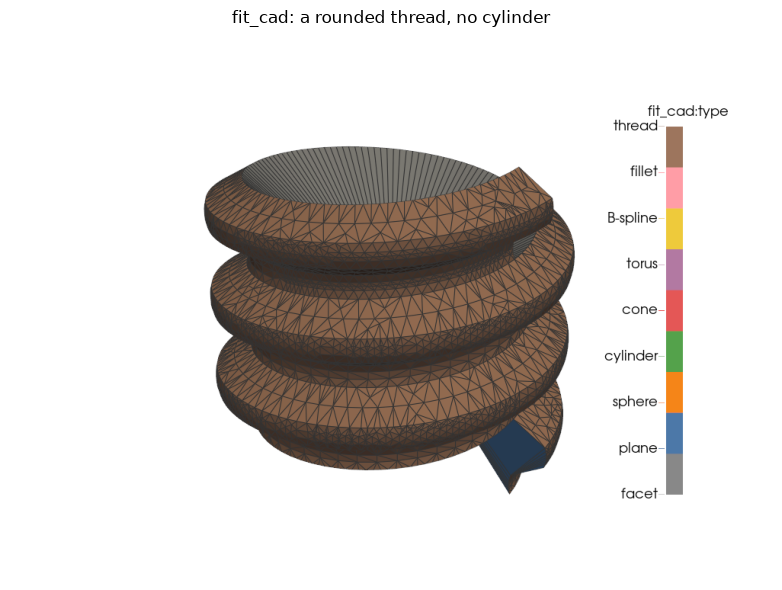

In [12]:
# Seen from the side each rounded edge faces.
cases = [('a fillet of varying radius', variable_fillet_block(), 3.0, 'fit_cad_variable_fillet', (0.6, 1.4, 0.9)),
         ('a blend between freeform faces', wavy_bar(), 3.0, 'fit_cad_blend', (0.6, 1.4, 0.9)),
         ('a rounded thread, no cylinder', rounded_thread_rod(), 0.0, 'fit_cad_rounded_thread', (1.0, -1.6, 0.9))]
if has_occt():
    for title, skin, ctol, save, view in cases:
        fitted = mp.fit_primitives(mp.segment(skin, curvature_tolerance=ctol))
        solid, cad = mp.fit_cad(fitted, return_report=True)
        print(f"{title:>32}: valid {cad['valid']}, {cad['num_faces']} faces -- "
              f"B-spline {cad['num_bspline']}, fillet {cad['num_fillet']} "
              f"(varying {cad['num_variable_fillet']}, blend {cad['num_blend']}), "
              f"thread {cad['num_helical']} (rounded {cad['num_rounded_thread']}), "
              f"faceted {cad['num_faceted_faces']}; deviation {cad['max_deviation']:.1e}"
              f" (tolerance {cad['tolerance']:.1e})")
        render(solid, f'fit_cad: {title}', scalars='fit_cad:type', cmap=FEATURE_COLORS,
               clim=[0, 8], annotations=FEATURES, save=save, view=view)
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON.')